In [1]:
import sys
from pathlib import Path

import fastf1
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn

print("Python:      ", sys.version.split()[0])
print("fastf1:      ", fastf1.__version__)
print("pandas:      ", pd.__version__)
print("numpy:       ", np.__version__)
print("matplotlib:  ", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)
print("Running from:", sys.executable)

assert ".venv" in sys.executable, "Wrong kernel! Switch to 'Python (f1-tyre-strategy)' (top right)."
print("✅ Using the project venv")

Python:       3.13.15
fastf1:       3.8.3
pandas:       2.3.3
numpy:        2.5.3
matplotlib:   3.11.2
scikit-learn: 1.9.1
Running from: /Users/brandonrichardson/Documents/GitHub/f1-tyre-strategy-simulator/.venv/bin/python
✅ Using the project venv


In [2]:
PROJECT_ROOT = Path.cwd().parent
print("Project root:", PROJECT_ROOT)
assert PROJECT_ROOT.name == "f1-tyre-strategy-simulator", "Notebook isn't in the notebooks/ folder!"

CACHE_DIR = PROJECT_ROOT / "data" / "fastf1_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
fastf1.Cache.enable_cache(str(CACHE_DIR))
print("✅ FastF1 cache enabled at:", CACHE_DIR)


Project root: /Users/brandonrichardson/Documents/GitHub/f1-tyre-strategy-simulator
✅ FastF1 cache enabled at: /Users/brandonrichardson/Documents/GitHub/f1-tyre-strategy-simulator/data/fastf1_cache


In [3]:
schedule = fastf1.get_event_schedule(2024, include_testing=False)
print("Number of 2024 races:", len(schedule))
schedule[["RoundNumber", "EventName", "Country", "EventDate"]].head(5)

Number of 2024 races: 24


,RoundNumber,EventName,Country,EventDate
1,1,Bahrain Grand Prix,Bahrain,2024-03-02
2,2,Saudi Arabian Grand Prix,Saudi Arabia,2024-03-09
3,3,Australian Grand Prix,Australia,2024-03-24
4,4,Japanese Grand Prix,Japan,2024-04-07
5,5,Chinese Grand Prix,China,2024-04-21


In [4]:
session = fastf1.get_session(2024, "Bahrain", "R")   # "R" = Race
session.load(laps=True, telemetry=False, weather=True, messages=True)

laps = session.laps.copy()
print("Laps table shape (rows, columns):", laps.shape)

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '55', '16', '63', '4', '44', '81', '14', '18', '24', '20', '3', '22', '23', '27', '31', '10', '77', '2']


Laps table shape (rows, columns): (1129, 31)


In [5]:
results = session.results.sort_values("Position")
winner = results.iloc[0]["Abbreviation"]
n_drivers = laps["Driver"].nunique()
max_lap = int(laps["LapNumber"].max())

print("Event:  ", session.event["EventName"], "|", session.event["EventDate"].date())
print("Winner: ", winner)
print("Drivers:", n_drivers)
print("Laps:   ", max_lap)

assert session.event["EventName"] == "Bahrain Grand Prix", "Wrong event loaded!"
assert winner == "VER", "Winner should be Verstappen. Check the session!"
assert max_lap == 57, "Bahrain 2024 was 57 laps."
assert n_drivers == 20, "Expected 20 drivers."
print("✅ All sanity checks passed")

Event:   Bahrain Grand Prix | 2024-03-02
Winner:  VER
Drivers: 20
Laps:    57
✅ All sanity checks passed


In [6]:
cols = ["Driver", "LapNumber", "LapTime", "Compound", "TyreLife", "Stint",
        "PitInTime", "PitOutTime", "TrackStatus", "IsAccurate"]
print(laps[cols].dtypes)
laps[cols].head(10)

Driver                  object
LapNumber              float64
LapTime        timedelta64[ns]
Compound                object
TyreLife               float64
Stint                  float64
PitInTime      timedelta64[ns]
PitOutTime     timedelta64[ns]
TrackStatus             object
IsAccurate                bool
dtype: object


,Driver,LapNumber,LapTime,Compound,TyreLife,Stint,PitInTime,PitOutTime,TrackStatus,IsAccurate
0,VER,1.0,0 days 00:01:37.284000,SOFT,4.0,1.0,NaT,NaT,12,False
1,VER,2.0,0 days 00:01:36.296000,SOFT,5.0,1.0,NaT,NaT,1,True
2,VER,3.0,0 days 00:01:36.753000,SOFT,6.0,1.0,NaT,NaT,1,True
3,VER,4.0,0 days 00:01:36.647000,SOFT,7.0,1.0,NaT,NaT,1,True
4,VER,5.0,0 days 00:01:37.173000,SOFT,8.0,1.0,NaT,NaT,1,True
5,VER,6.0,0 days 00:01:37.092000,SOFT,9.0,1.0,NaT,NaT,1,True
6,VER,7.0,0 days 00:01:37.038000,SOFT,10.0,1.0,NaT,NaT,1,True
7,VER,8.0,0 days 00:01:37.024000,SOFT,11.0,1.0,NaT,NaT,1,True
8,VER,9.0,0 days 00:01:37.229000,SOFT,12.0,1.0,NaT,NaT,1,True
9,VER,10.0,0 days 00:01:36.960000,SOFT,13.0,1.0,NaT,NaT,12,True


In [7]:
# TrackStatus codes: 1 = green, 2 = yellow, 4 = safety car, 5 = red flag,
# 6 = VSC deployed, 7 = VSC ending. One lap can contain several codes (e.g. "14"),
# so we check whether a code appears ANYWHERE in the value, not whether it equals it.
status = laps["TrackStatus"].astype(str)

laps["IsSafetyCar"] = status.str.contains("4")
laps["IsRedFlag"]   = status.str.contains("5")
laps["IsVSC"]       = status.str.contains("6") | status.str.contains("7")
laps["IsYellow"]    = status.str.contains("2")
laps["IsNeutralised"] = laps["IsSafetyCar"] | laps["IsVSC"] | laps["IsRedFlag"]

print("Unique TrackStatus values:", sorted(status.unique()))
print("\nLaps flagged (all drivers combined):")
print(laps[["IsSafetyCar", "IsVSC", "IsRedFlag", "IsYellow", "IsNeutralised"]].sum())

# Cross-check against the official race control log.
# Use the structured columns, not text search ("cheqUERED FLAG" matched "RED FLAG"!)
rc = session.race_control_messages
print("\nRace control message categories:")
print(rc["Category"].value_counts())

is_sc_or_vsc = rc["Category"].eq("SafetyCar")
is_red_flag  = rc["Flag"].eq("RED")
flag_msgs = rc[is_sc_or_vsc | is_red_flag]

print("\nRace control messages about SC / VSC / red flags:", len(flag_msgs))
flag_msgs[["Lap", "Category", "Flag", "Message"]].head(10)

Unique TrackStatus values: ['1', '12', '21']

Laps flagged (all drivers combined):
IsSafetyCar       0
IsVSC             0
IsRedFlag         0
IsYellow         42
IsNeutralised     0
dtype: int64

Race control message categories:
Category
Flag        37
Other       28
Drs          2
CarEvent     2
Name: count, dtype: int64

Race control messages about SC / VSC / red flags: 0


,Lap,Category,Flag,Message


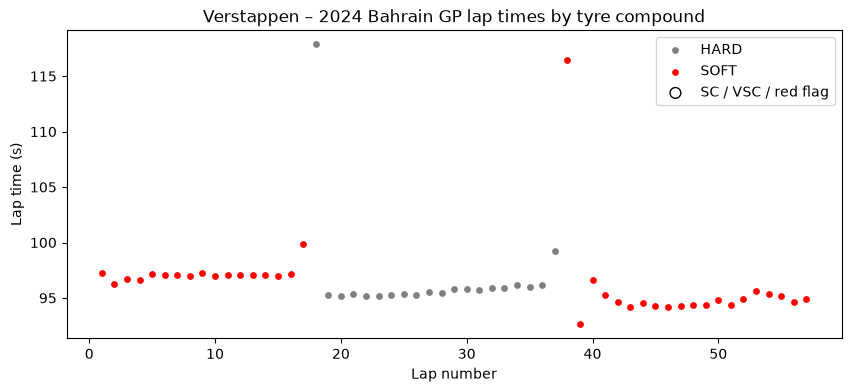

In [8]:
# New column, never overwrite the original LapTime
laps["LapTimeSeconds"] = laps["LapTime"].dt.total_seconds()

ver = laps[laps["Driver"] == "VER"]
colours = {"SOFT": "red", "MEDIUM": "gold", "HARD": "grey"}

fig, ax = plt.subplots(figsize=(10, 4))
for compound, group in ver.groupby("Compound"):
    ax.scatter(group["LapNumber"], group["LapTimeSeconds"],
               color=colours.get(compound, "blue"), label=compound, s=15)

neutral = ver[ver["IsNeutralised"]]
ax.scatter(neutral["LapNumber"], neutral["LapTimeSeconds"],
           facecolors="none", edgecolors="black", s=60, label="SC / VSC / red flag")

ax.set_xlabel("Lap number")
ax.set_ylabel("Lap time (s)")
ax.set_title("Verstappen – 2024 Bahrain GP lap times by tyre compound")
ax.legend()
plt.show()

In [9]:
size_mb = sum(f.stat().st_size for f in CACHE_DIR.rglob("*") if f.is_file()) / 1e6
print(f"Cache size: {size_mb:.1f} MB")

Cache size: 8.8 MB


In [10]:
quali = fastf1.get_session(2024, "Bahrain", "Q")   # "Q" = Qualifying
quali.load(laps=False, telemetry=False, weather=False, messages=False)

qres = quali.results[["Abbreviation", "Position", "Q1", "Q2", "Q3"]].copy()
# New column: each driver's best time across Q1, Q2 and Q3 (min skips blanks)
qres["BestQualiSeconds"] = qres[["Q1", "Q2", "Q3"]].min(axis=1).dt.total_seconds()

print("Drivers with a qualifying time:", qres["BestQualiSeconds"].notna().sum(), "of", len(qres))
qres.head(5)

core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
core           INFO 	Finished loading data for 20 drivers: ['1', '16', '63', '55', '11', '14', '4', '81', '44', '27', '22', '18', '23', '3', '20', '77', '24', '2', '31', '10']


Drivers with a qualifying time: 20 of 20


,Abbreviation,Position,Q1,Q2,Q3,BestQualiSeconds
1,VER,1.0,0 days 00:01:30.031000,0 days 00:01:29.374000,0 days 00:01:29.179000,89.179
16,LEC,2.0,0 days 00:01:30.243000,0 days 00:01:29.165000,0 days 00:01:29.407000,89.165
63,RUS,3.0,0 days 00:01:30.350000,0 days 00:01:29.922000,0 days 00:01:29.485000,89.485
55,SAI,4.0,0 days 00:01:29.909000,0 days 00:01:29.573000,0 days 00:01:29.507000,89.507
11,PER,5.0,0 days 00:01:30.221000,0 days 00:01:29.932000,0 days 00:01:29.537000,89.537


In [11]:
ver_quali = qres.loc[qres["Abbreviation"] == "VER", "BestQualiSeconds"].iloc[0]

# Clean laps only: not pit in/out laps, accurate timing, not neutralised
is_clean = (
    laps["PitInTime"].isna()
    & laps["PitOutTime"].isna()
    & laps["IsAccurate"]
    & ~laps["IsNeutralised"]
)
ver_clean = laps[(laps["Driver"] == "VER") & is_clean].copy()

# New column, the target we'll predict
ver_clean["DeltaToQuali"] = ver_clean["LapTimeSeconds"] - ver_quali

print(f"VER best qualifying lap: {ver_quali:.3f} s")
print("Clean VER race laps:", len(ver_clean))
print(ver_clean["DeltaToQuali"].describe().round(3))

VER best qualifying lap: 89.179 s
Clean VER race laps: 52
count    52.000
mean      6.475
std       1.067
min       3.429
25%       5.740
50%       6.350
75%       7.495
max       8.050
Name: DeltaToQuali, dtype: float64


## Notes & findings – 00 Setup check

**Environment**
- Python 3.13.15 running from the project `.venv`; Jupyter kernel `Python (f1-tyre-strategy)`.
- Versions (to pin for deployment): fastf1 3.8.3, pandas 2.3.3, numpy 2.5.3, matplotlib 3.11.2, scikit-learn 1.9.1.
- FastF1 cache in `data/fastf1_cache` (git-ignored); the second load of a race used the cache only. One race ≈ 8.8 MB, so 2022–2025 (~90 races) ≈ 800 MB.

**Sanity checks – all passed**
- 2024 calendar: 24 races; round 1 = Bahrain GP, 2 March 2024.
- 2024 Bahrain GP: winner VER, 20 drivers, 57 laps.
- Laps table: 1,129 rows × 31 columns (11 fewer than 20 × 57 = 1,140, because lapped drivers and any retirements complete fewer laps).

**Data observations**
- `TyreLife` records the tyre's true age, including qualifying use: VER started on 4-lap-old softs on lap 1.
- Lap 1 is flagged `IsAccurate = False` (standing start) → exclude from training.
- `LapNumber`, `TyreLife`, `Stint` are stored as floats (they allow blanks) → create integer versions in Stage 3.

**Track status**
- Only codes 1 (green) and 2 (yellow) appeared: 0 safety car, 0 VSC, 0 red-flag laps, 42 lap records with a yellow.
- Race control log agrees: 0 SafetyCar / red-flag messages (categories: Flag 37, Other 28, Drs 2, CarEvent 2).
- VER's yellow lap 10 was not slower, because yellows are local → test the effect of yellows in Stage 3 before excluding them.
- Bug found and fixed: a text search for "RED FLAG" matched "CHEQUERED FLAG". Now using the structured `Category` and `Flag` columns with exact matches.

**First look at strategy (VER)**
- SOFT (laps 1–16) → HARD (18–37) → SOFT (38–57); pitted on laps 17 and 37.
- Pit loss ≈ 25 s in total (in-lap ≈ +4 s, out-lap ≈ +21 s vs a ~95–96 s normal lap).
- Fastest lap ≈ 92.6 s on lap 39 (fresh softs, low fuel).
- Hard stint looks nearly flat (≈ 95.1 → 96.0 s) because fuel burn-off hides tyre wear → the model must separate fuel effect from tyre wear.
- Limitation to note: a leading driver manages pace, which the model cannot see.

**Qualifying reference (Stage 1 check)**
- 2024 Bahrain qualifying: 20 of 20 drivers have a time; VER best 89.179 s (pole).
- Best of Q1/Q2/Q3 does not follow grid order: LEC's best (89.165 s, in Q2) was faster than VER's pole lap → `BestQualiSeconds` measures pace, not grid position.
- VER `DeltaToQuali` on 52 clean laps (57 minus lap 1, two in-laps, two out-laps): mean 6.475 s, median 6.350 s, std 1.067 s, range 3.429 s (lap 39, fresh softs, light fuel) to 8.050 s (lap 9, heavy fuel, used softs).
- A ~4.6 s within-race spread for one driver is what fuel and tyre effects must explain; the model has to beat simply predicting the average.